In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data and add cost per prompt

MODELS = ["qwen3:1.7b", "qwen3:4b", "qwen3:8b"]   # small → large

# Simulated price in $ per 1M tokens, scaled by model size
PRICE = {"qwen3:1.7b": 0.05, "qwen3:4b": 0.15, "qwen3:8b": 0.50}

df = pd.read_csv("results/benchmark.csv")   # switch to benchmark.csv later
df["cost"] = (df["prompt_tokens"] + df["output_tokens"]) * df["model"].map(PRICE) / 1e6

print(df.shape)
df.head()

(180, 13)


,qid,task,subject,model,correct,latency_s,prompt_tokens,output_tokens,answer,gold,prompt,raw_output,cost
0,gsm8k-1309,gsm8k,NaN,qwen3:1.7b,0,1.4587,113,99,1880,2280,The girls are trying to raise money for a carn...,"- Kim raises $320 more than Alexandra, who rai...",0.000011
1,gsm8k-228,gsm8k,NaN,qwen3:1.7b,1,1.6410,107,114,1,1,Kalinda is working on a 360 piece puzzle with ...,Let's calculate their combined rate:\n\n- Kali...,0.000011
2,gsm8k-51,gsm8k,NaN,qwen3:1.7b,1,1.3171,101,93,5,5,Tom's ship can travel at 10 miles per hour. H...,Tom's ship travels at 10 mph going and 6 mph r...,0.000010
3,gsm8k-563,gsm8k,NaN,qwen3:1.7b,1,1.4335,101,91,12,12,James decides to buy birthday candles for his ...,The other son is 12 - 4 = 8 years old. \nJame...,0.000010
4,gsm8k-501,gsm8k,NaN,qwen3:1.7b,1,1.6795,114,101,273,273,Mariah’s grandma was teaching her to knit. Mar...,"Mariah used $ \frac{1}{4} $ of a skein, and he...",0.000011


In [2]:
# Summary per task and model
df.groupby(["task", "model"]).agg(
    accuracy=("correct", "mean"),
    avg_latency_s=("latency_s", "mean"),
    avg_tokens=("output_tokens", "mean"),
    avg_cost=("cost", "mean"),
    n=("correct", "size"),
).round({"accuracy": 3, "avg_latency_s": 3, "avg_tokens": 2, "avg_cost": 6, "n": 1})

accuracy  avg_latency_s  avg_tokens  avg_cost   n
task  model                                                        
gsm8k qwen3:1.7b     0.767          1.758      118.90  0.000012  30
      qwen3:4b       0.533         13.146      438.50  0.000082  30
      qwen3:8b       0.933          6.593      115.43  0.000114  30
mmlu  qwen3:1.7b     0.500          0.232        7.03  0.000008  30
      qwen3:4b       0.300          2.179       64.00  0.000031  30
      qwen3:8b       0.567          0.826        3.60  0.000076  30

In [3]:
# Did any model leak <think> text?
# if "had_think" in df.columns:
#     print(df.groupby("model")["had_think"].mean())

# What model had answers missing
print("Models with missing answers:")
display(df[["model", "answer"]][df["answer"].isna()])

# How many answers could not be parsed at all?
print("Missing answers per model: ")
print(df["answer"].isna().groupby(df["model"]).mean())

Models with missing answers:


,model,answer
104,qwen3:4b,NaN
109,qwen3:4b,NaN
113,qwen3:4b,NaN


Missing answers per model: 
model
qwen3:1.7b    0.00
qwen3:4b      0.05
qwen3:8b      0.00
Name: answer, dtype: float64


In [4]:
# Reshape data into wide table, with index = question id, columns = model used, value (i, j) = correctness of the model given the question
wide = df.pivot(index="qid", columns="model", values="correct")[MODELS]

# Turns each row into a string pattern -> "101" means that model_A was correct, model_B was wrong and model_C was correct
patterns = wide.astype(int).astype(str).agg("".join, axis=1)  # axis = 1 goes row by row

# Retrieve for each string pattern the number of values found
print("Pattern = correct? for", MODELS)
print(patterns.value_counts())

Pattern = correct? for ['qwen3:1.7b', 'qwen3:4b', 'qwen3:8b']
111    18
101    17
001     8
000     8
010     4
011     2
100     2
110     1
Name: count, dtype: int64


In [5]:
print(df["qid"][df["qid"] == "gsm8k-1309"].value_counts())

qid
gsm8k-1309    3
Name: count, dtype: int64


In [6]:
def evaluate(d: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for m in MODELS:
        sub = d[d["model"] == m]  # keep only the specific lines for each model
        rows.append({"policy": f"always {m}", "accuracy": sub["correct"].mean(),
                     "avg_cost": sub["cost"].mean(), "avg_latency_s": sub["latency_s"].mean()})

    # Random: picking a model uniformly = the average across models
    # Basically the metrics is the mean for all input models
    per_model = d.groupby("model")[["correct", "cost", "latency_s"]].mean()
    rows.append({"policy": "random", "accuracy": per_model["correct"].mean(),
                 "avg_cost": per_model["cost"].mean(), "avg_latency_s": per_model["latency_s"].mean()})

    # Oracle: for each question, the cheapest correct model (or cheapest overall if none is correct)
    # Sort by qid ascending, correct descending (1=correct comes first of 0=incorrect), and cost ascending(lowest cost first)
    # Remore duplicted ids => because each model solved the same questions, keep only the first that appears (cheapest and correct one)
    oracle = (d.sort_values(["qid", "correct", "cost"], ascending=[True, False, True])
                .drop_duplicates("qid"))
    rows.append({"policy": "oracle", "accuracy": oracle["correct"].mean(),
                 "avg_cost": oracle["cost"].mean(), "avg_latency_s": oracle["latency_s"].mean()})

    return pd.DataFrame(rows).round({"accuracy": 3, "avg_cost": 6, "avg_latency": 3})

results = {}
for task in df["task"].unique():
    results[task] = evaluate(df[df["task"] == task])

print("Results for GSM8K questions: ")
print(results["gsm8k"])

print("Results for MMLU questions: ")
print(results["mmlu"])

Results for GSM8K questions: 
              policy  accuracy  avg_cost  avg_latency_s
0  always qwen3:1.7b     0.767  0.000012       1.757557
1    always qwen3:4b     0.533  0.000082      13.145940
2    always qwen3:8b     0.933  0.000114       6.592710
3             random     0.744  0.000069       7.165402
4             oracle     0.933  0.000031       3.029350
Results for MMLU questions: 
              policy  accuracy  avg_cost  avg_latency_s
0  always qwen3:1.7b     0.500  0.000008       0.232217
1    always qwen3:4b     0.300  0.000031       2.179303
2    always qwen3:8b     0.567  0.000076       0.825767
3             random     0.456  0.000038       1.079096
4             oracle     0.800  0.000018       0.600107


In [7]:
oracle = (df.sort_values(["qid", "correct", "cost"], ascending=[True, False, True])
            .drop_duplicates("qid"))
oracle.groupby("task")["model"].value_counts(normalize=True).round(2)

task   model     
gsm8k  qwen3:1.7b    0.83
       qwen3:8b      0.13
       qwen3:4b      0.03
mmlu   qwen3:1.7b    0.70
       qwen3:4b      0.17
       qwen3:8b      0.13
Name: proportion, dtype: float64

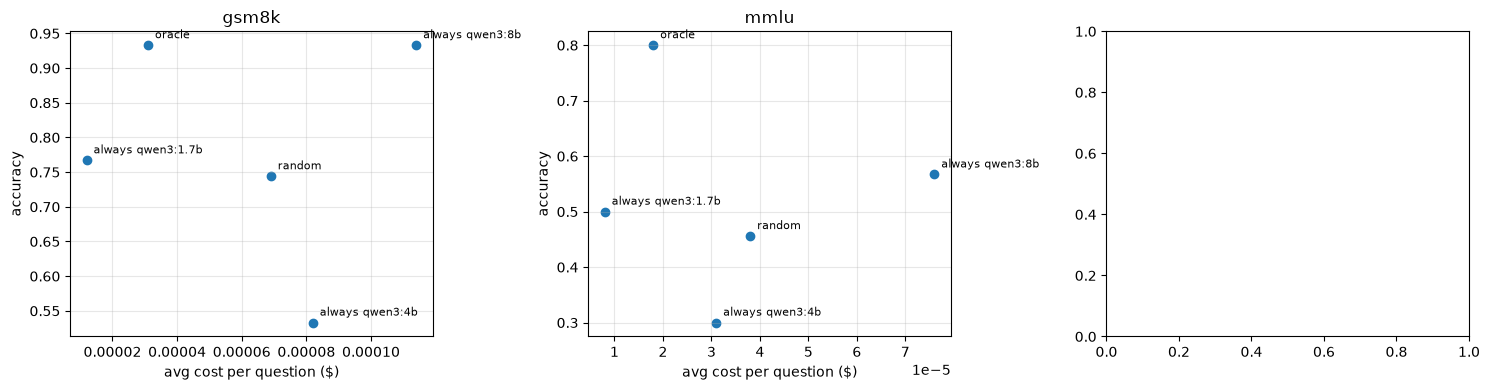

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, res) in zip(axes, results.items()):
    ax.scatter(res["avg_cost"], res["accuracy"])
    for _, r in res.iterrows():
        ax.annotate(r["policy"], (r["avg_cost"], r["accuracy"]),
                    textcoords="offset points", xytext=(5, 5), fontsize=8)
    ax.set_title(name)
    ax.set_xlabel("avg cost per question ($)")
    ax.set_ylabel("accuracy")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
df["had_think"] = df["raw_output"].str.contains("<think>", na=False)
df.groupby("model")[["had_think", "output_tokens"]].mean()

,had_think,output_tokens
model,,
qwen3:1.7b,0.0,62.966667
qwen3:4b,0.0,251.250000
qwen3:8b,0.0,59.516667


In [11]:
df["chars"] = df["raw_output"].fillna("").str.len()
df["chars_per_token"] = df["chars"] / df["output_tokens"]
df.groupby("model")[["output_tokens", "chars", "chars_per_token"]].mean().round(1)

,output_tokens,chars,chars_per_token
model,,,
qwen3:1.7b,63.0,155.1,2.9
qwen3:4b,251.2,811.3,3.7
qwen3:8b,59.5,144.7,1.8


In [14]:
cap = df["task"].map({"gsm8k": 512, "mmlu": 64})
df["hit_cap"] = df["output_tokens"] >= cap
df["no_answer"] = df["answer"].isna()
df.groupby(["model", "task"])[["hit_cap", "no_answer", "correct"]].mean().round(2)

hit_cap  no_answer  correct
model      task                              
qwen3:1.7b gsm8k     0.00        0.0     0.77
           mmlu      0.00        0.0     0.50
qwen3:4b   gsm8k     0.57        0.0     0.53
           mmlu      1.00        0.1     0.30
qwen3:8b   gsm8k     0.00        0.0     0.93
           mmlu      0.00        0.0     0.57